En el anterior ejemplo se ha obtenido y verificado un clasificador lineal binario (perceptrón) para el dataset que resulta al eliminar una de las tres clases. Haz lo mismo para los datasets que resultan de eliminar cada una de las otras dos clases del dataset original, para dejar solo dos. Empieza la actividad copiando el ejemplo anterior, y añade al final lo nuevo que se pide para esta actividad.

Tasa de aciertos: 0.99


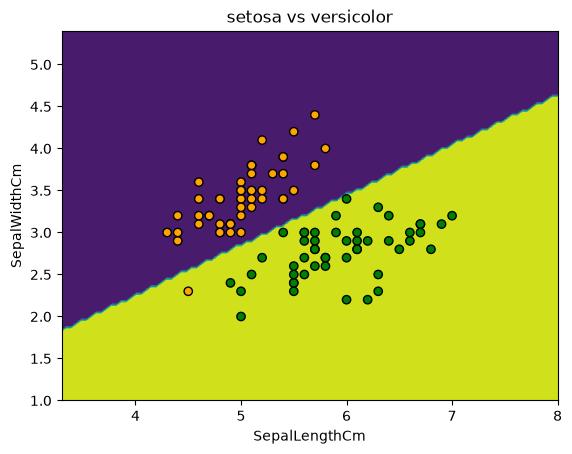

Iris-versicolor vs Iris-virginica -> Tasa de aciertos: 0.5


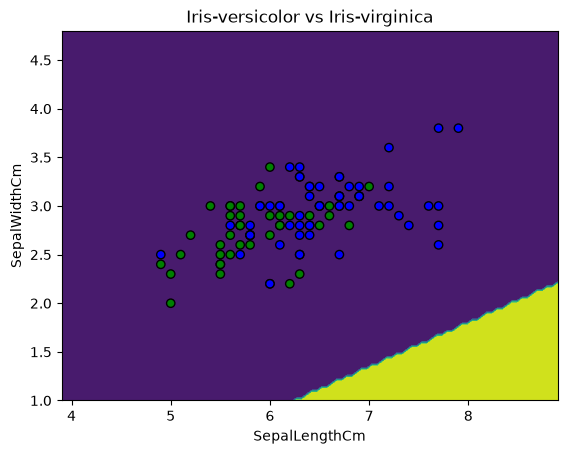

Iris-setosa vs Iris-virginica -> Tasa de aciertos: 0.99


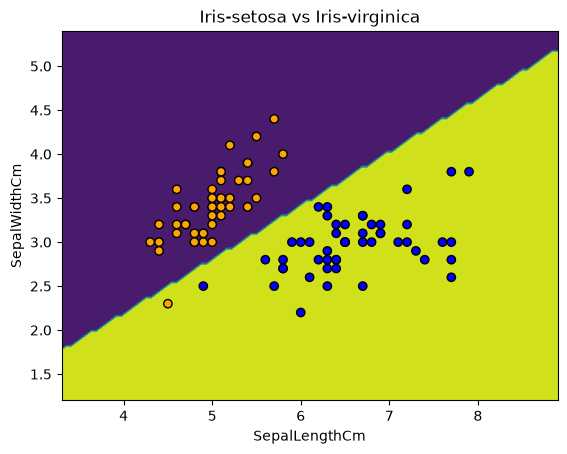

In [7]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score
from sklearn.inspection import DecisionBoundaryDisplay

# ============================================================
# EJEMPLO ORIGINAL: setosa vs versicolor (se elimina virginica)
# ============================================================
df_orig = pd.read_csv(r"C:\Users\ia\Desktop\IABD\SAA\UD3\iris.csv")

df = df_orig[df_orig['Species'].isin(['Iris-setosa', 'Iris-versicolor'])]

x = df[['SepalLengthCm', 'SepalWidthCm']]
y = df['Species']

clf = Perceptron()
clf.fit(x, y)

y_pred = clf.predict(x)
print('Tasa de aciertos:', accuracy_score(y, y_pred))

DecisionBoundaryDisplay.from_estimator(clf, x, response_method="predict")
colores = {'Iris-setosa': 'orange', 'Iris-versicolor': 'green'}
plt.scatter(x['SepalLengthCm'], x['SepalWidthCm'], c=y.map(colores), edgecolor='k')
plt.xlabel("SepalLengthCm")
plt.ylabel("SepalWidthCm")
plt.title("setosa vs versicolor")
plt.show()


# ============================================================
# ACTIVIDAD: las otras dos combinaciones de clases
# ============================================================
def entrenar_y_mostrar(df_completo, clase_a, clase_b, color_a, color_b):
    # Dataset con solo dos clases
    d = df_completo[df_completo['Species'].isin([clase_a, clase_b])]
    X = d[['SepalLengthCm', 'SepalWidthCm']]
    Y = d['Species']

    # Entrenamiento
    modelo = Perceptron()
    modelo.fit(X, Y)

    # Verificación: tasa de aciertos
    acc = accuracy_score(Y, modelo.predict(X))
    print(f'{clase_a} vs {clase_b} -> Tasa de aciertos: {acc}')

    # Fronteras de decisión + datos
    plt.figure()
    DecisionBoundaryDisplay.from_estimator(modelo, X, response_method="predict", ax=plt.gca())
    plt.scatter(X['SepalLengthCm'], X['SepalWidthCm'],
                c=Y.map({clase_a: color_a, clase_b: color_b}), edgecolor='k')
    plt.xlabel("SepalLengthCm")
    plt.ylabel("SepalWidthCm")
    plt.title(f"{clase_a} vs {clase_b}")
    plt.show()

# Se elimina setosa -> versicolor vs virginica
entrenar_y_mostrar(df_orig, 'Iris-versicolor', 'Iris-virginica', 'green', 'blue')

# Se elimina versicolor -> setosa vs virginica
entrenar_y_mostrar(df_orig, 'Iris-setosa', 'Iris-virginica', 'orange', 'blue')